# Wine Quality Assessment Using Physicochemical Properties

**Case study:** can lab measurements explain the quality score that tasters give a wine?

**Dataset:** Vinho Verde wine from Portugal (Cortez et al., 2009). There are two files, red (1599 samples) and white (4898 samples). I am using the **red wine** file for this whole notebook, so every number and comment below refers to red wine.

**Citation:** P. Cortez, A. Cerdeira, F. Almeida, T. Matos and J. Reis. *Modeling wine preferences by data mining from physicochemical properties.* Decision Support Systems, Elsevier, 47(4):547-553, 2009.

**Plan**
1. Task 1 - basic statistics (mean, median, mode, std, skewness, CV, Pearson r)
2. Task 2 - EDA (histogram, box plot, heatmap)
3. Task 3 - multiple linear regression
4. Task 4 - what this means for the company

## 0. Setting up and loading the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

In [2]:
# the file uses ; as separator, not comma
df = pd.read_csv("winequality-red.csv", sep=";")
print(df.shape)
df.head()

(1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
df.info()
print("\nmissing values:", df.isnull().sum().sum())
print("duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

missing values: 0
duplicate rows: 240


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


The data is clean: 1599 rows, 11 inputs and the `quality` column, no missing values (this matches the `.names` file). One thing I noticed is that 240 rows are exact duplicates. Since two different bottles can easily have identical lab readings and the same score, I am **keeping them** and will mention this again in the limitations.

# Task 1 - Statistical analysis

### 1a. Mean, median, mode, standard deviation and skewness

In [5]:
cols = ["alcohol", "volatile acidity", "residual sugar"]

summary = pd.DataFrame({
    "mean": df[cols].mean(),
    "median": df[cols].median(),
    "mode": [df[c].mode()[0] for c in cols],   # mode() can return several values, taking the first
    "std": df[cols].std(),
    "skewness": df[cols].skew(),
})
summary.round(3)

,mean,median,mode,std,skewness
alcohol,10.423,10.20,9.5,1.066,0.861
volatile acidity,0.528,0.52,0.6,0.179,0.672
residual sugar,2.539,2.20,2.0,1.410,4.541


**Observations**

- **Alcohol:** mean (10.42) is a bit above the median (10.2) and the mode is 9.5, so it has a mild right tail. Skewness is 0.86, moderately right skewed.
- **Volatile acidity:** mean 0.528 and median 0.52 are almost the same, skewness 0.67. It is fairly symmetric with a small right tail.
- **Residual sugar:** mean 2.54 vs median 2.2 and the skewness is 4.54, which is very high. A small number of wines have a lot of sugar (the max is 15.5) and they pull the mean up. This one is clearly not normal.

For all three the mean is greater than the median, which is what a positive skew looks like.

### 1b. Which attribute has the greatest relative variability?

Standard deviation cannot be compared directly here because the three variables are on different scales (alcohol is around 10, volatile acidity around 0.5). So I use the **coefficient of variation (CV = std / mean x 100)**, which has no units.

In [6]:
cv = (df[cols].std() / df[cols].mean() * 100).round(2)
print(cv.sort_values(ascending=False))
print("\nHighest relative variability:", cv.idxmax())

residual sugar      55.54
volatile acidity    33.92
alcohol             10.22
dtype: float64

Highest relative variability: residual sugar


**Residual sugar has the highest CV (about 55.5%)**, followed by volatile acidity (about 33.9%) and alcohol (about 10.2%). Alcohol has a larger standard deviation than volatile acidity (1.07 vs 0.18), but that is only because it is measured on a bigger scale. Relative to its mean alcohol is actually the most stable of the three. Residual sugar varies the most between wines, which fits with its very high skewness.

### 1c. Pearson correlation between alcohol and quality

In [7]:
r, p = stats.pearsonr(df["alcohol"], df["quality"])
print(f"Pearson r = {r:.4f}")
print(f"p-value   = {p:.2e}")

Pearson r = 0.4762
p-value   = 2.83e-91


**Interpretation:** r is about **+0.48**. The sign is positive, so wines with higher alcohol tend to get higher quality scores. The strength is **moderate** (roughly 0.3 to 0.5 is moderate): alcohol is clearly related to quality but it does not decide it alone. r squared is about 0.23, so alcohol by itself accounts for roughly 23% of the variation in quality. The p-value is tiny so the relationship is statistically significant, but with 1599 samples even weak correlations would be significant, so strength matters more than the p-value here. Also this is correlation only, it does not show that adding alcohol would make a wine better.

# Task 2 - Exploratory data analysis

### 2a. Histogram of quality scores

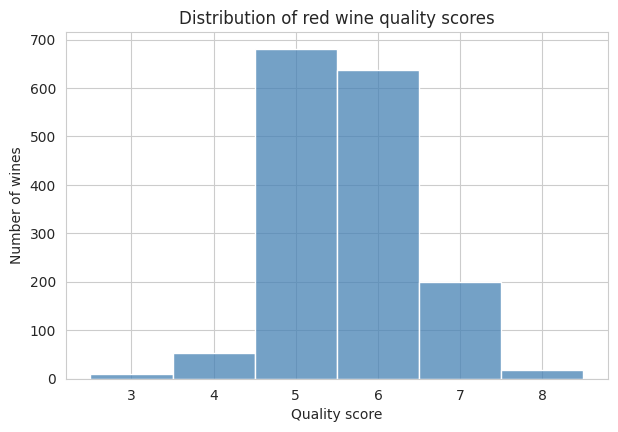

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

skewness: 0.218


In [8]:
plt.figure(figsize=(7, 4.5))
sns.histplot(df["quality"], bins=np.arange(2.5, 9.5, 1), color="steelblue", edgecolor="white")
plt.xlabel("Quality score")
plt.ylabel("Number of wines")
plt.title("Distribution of red wine quality scores")
plt.show()

print(df["quality"].value_counts().sort_index())
print("\nskewness:", round(df["quality"].skew(), 3))

**Interpretation:** the scores only go from 3 to 8, even though the scale is 0 to 10, so nobody got a 0-2 or a 9-10. Most wines are in the middle: scores 5 and 6 together make up about 83% of the data (681 + 638 out of 1599). Very bad (3) and excellent (8) wines are rare, only 10 and 18 samples. The shape is roughly bell like and nearly symmetric (skewness is small) but it is very peaked around 5-6. The classes are **imbalanced**, which matters later because a regression model will have very few examples of the extremes to learn from.

### 2b. Box plot of alcohol by quality

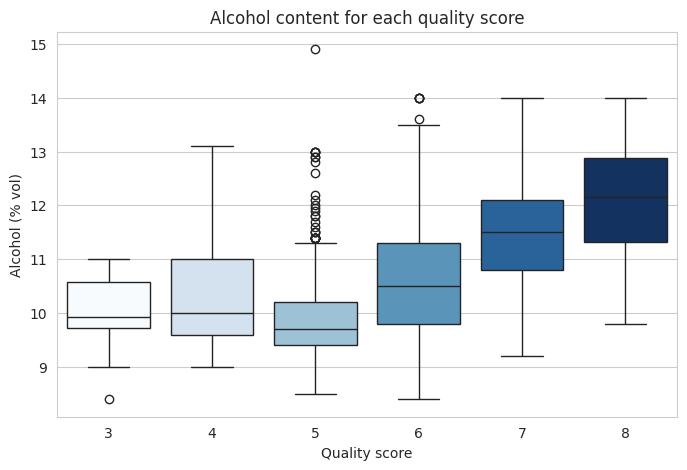

         count  median   mean
quality                      
3           10    9.93   9.96
4           53   10.00  10.27
5          681    9.70   9.90
6          638   10.50  10.63
7          199   11.50  11.47
8           18   12.15  12.09


In [9]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="quality", y="alcohol", hue="quality", data=df, palette="Blues", legend=False)
plt.title("Alcohol content for each quality score")
plt.xlabel("Quality score")
plt.ylabel("Alcohol (% vol)")
plt.show()

print(df.groupby("quality")["alcohol"].agg(["count", "median", "mean"]).round(2))

In [10]:
# counting outliers per quality group using the usual 1.5*IQR rule (same rule the box plot uses)
def count_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

df.groupby("quality")["alcohol"].apply(count_outliers).rename("outliers")

,outliers
quality,
3,1
4,0
5,30
6,5
7,0
8,0


**Observations**

- From quality 5 upwards the median alcohol keeps rising: about 9.7 for quality 5, 10.5 for 6, 11.5 for 7 and about 12.2 for 8. This agrees with the positive correlation from Task 1.
- At the low end the pattern is not steady. Quality 3 and 4 have medians of about 9.9 and 10.0, which are actually higher than quality 5 (9.7). There are only 10 and 53 wines in those groups so I would not read too much into it.
- **Outliers:** quality 5 has the most outlier points by far (30), almost all of them high alcohol values (11.4 up to 14.9). Quality 6 has 5 high outliers (13.6 to 14.0) and quality 3 has one low value (8.4). Quality 4, 7 and 8 have none. So there are plenty of high alcohol wines that still only got an average score, which means alcohol alone does not guarantee a high rating.
- The boxes for neighbouring scores overlap a lot (for example 5 vs 6), so alcohol cannot separate them cleanly.

### 2c. Correlation heatmap

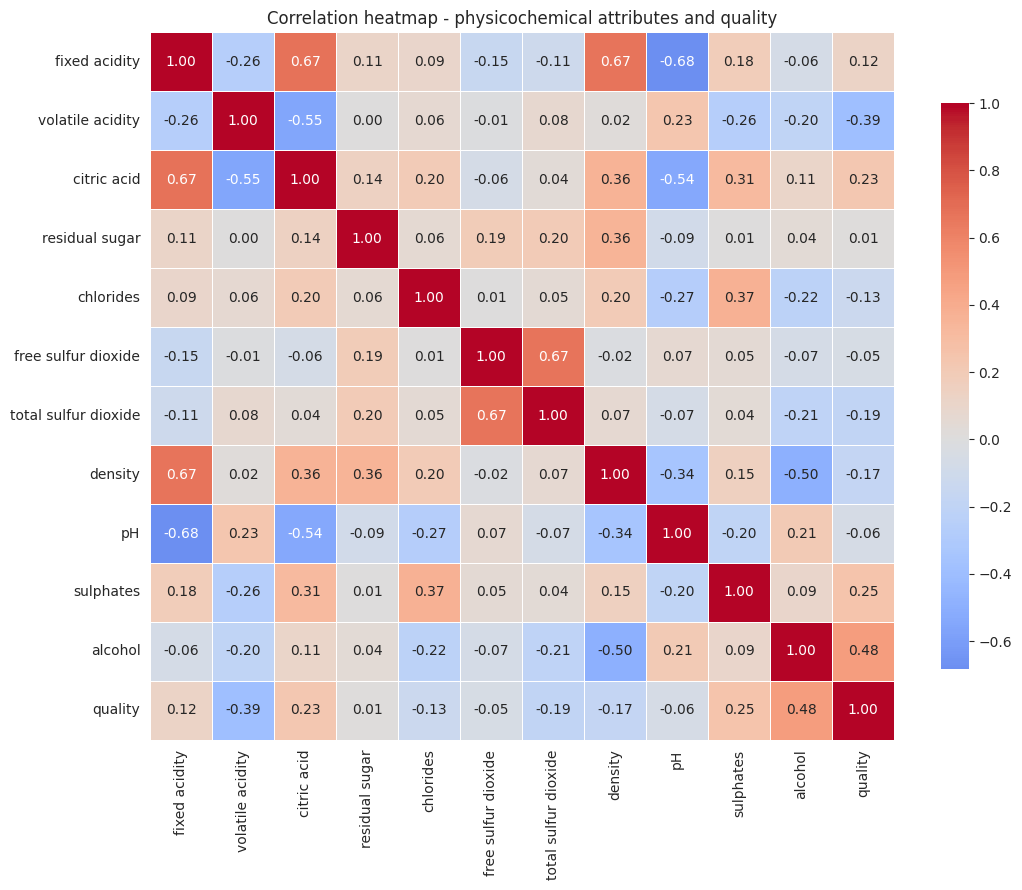

In [11]:
corr = df.corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation heatmap - physicochemical attributes and quality")
plt.tight_layout()
plt.show()

Things I can see in the heatmap besides the quality row:

- fixed acidity and citric acid (+0.67), fixed acidity and density (+0.67): acidic wines are denser.
- fixed acidity and pH (-0.68): more acid means lower pH, which is just chemistry.
- free sulfur dioxide and total sulfur dioxide (+0.67), and citric acid and volatile acidity (-0.55).
- alcohol and density (-0.50): alcohol is lighter than water so more alcohol means lower density.

So several inputs are correlated with each other, which I need to keep in mind for the regression (multicollinearity).

### 2d. Two attributes most strongly associated with quality

In [12]:
q_corr = corr["quality"].drop("quality")
ranked = q_corr.reindex(q_corr.abs().sort_values(ascending=False).index)
print(ranked.round(3))

alcohol                 0.476
volatile acidity       -0.391
sulphates               0.251
citric acid             0.226
total sulfur dioxide   -0.185
density                -0.175
chlorides              -0.129
fixed acidity           0.124
pH                     -0.058
free sulfur dioxide    -0.051
residual sugar          0.014
Name: quality, dtype: float64


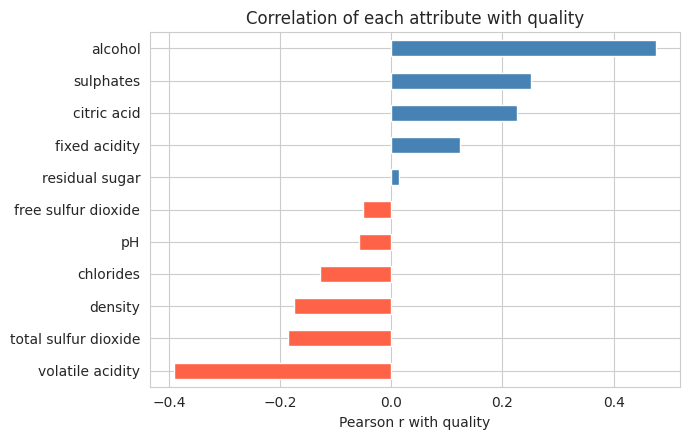

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ranked.sort_values().plot(kind="barh", color=["tomato" if v < 0 else "steelblue" for v in ranked.sort_values()], ax=ax)
ax.set_xlabel("Pearson r with quality")
ax.set_title("Correlation of each attribute with quality")
plt.tight_layout()
plt.show()

The two with the largest absolute correlation are:

1. **Alcohol, r = +0.476 (positive)**: higher alcohol goes with higher quality.
2. **Volatile acidity, r = -0.391 (negative)**: higher volatile acidity goes with lower quality. Volatile acidity is mainly acetic acid, and too much of it gives a vinegar smell and taste, so it makes sense that tasters mark those wines down.

The next ones are sulphates (+0.25) and citric acid (+0.23) but they are clearly weaker. Residual sugar (0.01), free sulfur dioxide (-0.05) and pH (-0.06) are almost unrelated to quality on their own.

# Task 3 - Predictive modelling

### 3a and 3b. Multiple linear regression with an 80/20 split

Target is `quality`, features are the 11 lab measurements. The split is 80% train and 20% test with `random_state=42`.

In [14]:
X = df.drop(columns="quality")
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train:", X_train.shape, " test:", X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

train: (1279, 11)  test: (320, 11)


In [15]:
coef_table = pd.DataFrame({"coefficient": model.coef_}, index=X.columns)
print("intercept:", round(model.intercept_, 3))
coef_table.round(4)

intercept: 14.355


,coefficient
fixed acidity,0.0231
volatile acidity,-1.0013
citric acid,-0.1408
residual sugar,0.0066
chlorides,-1.8065
free sulfur dioxide,0.0056
total sulfur dioxide,-0.0036
density,-10.3516
pH,-0.3937
sulphates,0.8412


These raw coefficients cannot be compared with each other because each one is "per one unit" of its own variable (density changes in the third decimal place while sulfur dioxide is in tens). That is why I use standardized coefficients in 3d. Density has a huge raw coefficient only because its scale is so small.

### 3c. MAE, MSE, RMSE and R-squared on the test set

In [16]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R^2  : {r2:.4f}")

MAE  : 0.5035
MSE  : 0.3900
RMSE : 0.6245
R^2  : 0.4032


**Interpretation**

- **MAE = 0.50:** on average the prediction is off by about half a quality point.
- **RMSE = 0.62:** a bit higher than MAE because RMSE punishes big errors more.
- **R-squared = 0.40:** the model explains only about 40% of the variation in quality on unseen wines. The other 60% comes from something the 11 measurements are not capturing.

For a scale that only really uses 5 values (3 to 8), an error of half a point is quite large.

In [17]:
# train score vs test score, to check for overfitting
print("R2 train:", round(model.score(X_train, y_train), 4))
print("R2 test :", round(r2, 4))

# baseline: always predict the training mean
baseline = np.full(len(y_test), y_train.mean())
print("\nBaseline (predict the mean) RMSE:", round(np.sqrt(mean_squared_error(y_test, baseline)), 4))
print("Model RMSE                      :", round(rmse, 4))

R2 train: 0.348
R2 test : 0.4032

Baseline (predict the mean) RMSE: 0.8107
Model RMSE                      : 0.6245


Train R-squared (0.35) is actually a little lower than test R-squared (0.40), so there is no sign of overfitting. The test set was probably just a slightly easier split, which is one more reason not to trust a single split too much. The model beats the "always guess the mean" baseline (RMSE 0.62 vs 0.81), but it is not a huge improvement, which says the same thing as the R-squared: useful but limited.

### 3d. Most influential predictors (standardized coefficients) and multicollinearity

To compare predictors fairly I standardize the features (mean 0, std 1) using the training data and refit. Each coefficient then says how much quality changes (in points) for a one standard deviation increase in that feature.

In [18]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)

model_s = LinearRegression().fit(X_train_s, y_train)

std_coef = pd.Series(model_s.coef_, index=X.columns)
std_coef = std_coef.reindex(std_coef.abs().sort_values(ascending=False).index)
std_coef.round(4)

,0
alcohol,0.2966
volatile acidity,-0.1794
sulphates,0.1468
total sulfur dioxide,-0.1200
chlorides,-0.0891
pH,-0.0606
free sulfur dioxide,0.0580
fixed acidity,0.0398
citric acid,-0.0275
density,-0.0192


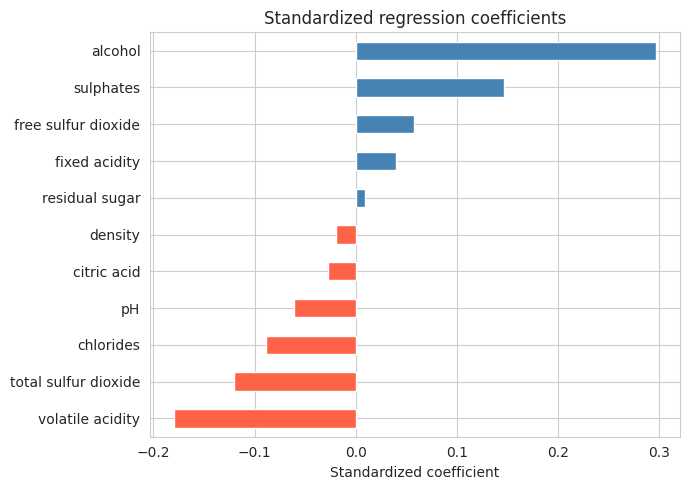

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))
std_coef.sort_values().plot(kind="barh", color=["tomato" if v < 0 else "steelblue" for v in std_coef.sort_values()], ax=ax)
ax.set_xlabel("Standardized coefficient")
ax.set_title("Standardized regression coefficients")
plt.tight_layout()
plt.show()

The two most influential predictors are **alcohol (+0.30)** and **volatile acidity (-0.18)**. Sulphates (+0.15) is third. Alcohol having the biggest effect and volatile acidity second matches what we found with the plain correlations in 2d, so the result is consistent.

**Multicollinearity check.** From the heatmap several inputs are correlated with each other, and when that happens the coefficients can become unstable and hard to interpret. So before trusting these numbers I checked the Variance Inflation Factor (VIF). A common rule of thumb is that VIF above 5 is worth a look and above 10 is a serious problem.

In [20]:
X_vif = X_train.copy()
X_vif.insert(0, "const", 1.0)   # VIF needs an intercept column

vif = pd.DataFrame({
    "feature": X_vif.columns[1:],
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])]
}).sort_values("VIF", ascending=False)
vif.round(2).reset_index(drop=True)

,feature,VIF
0,fixed acidity,7.37
1,density,6.02
2,pH,3.28
3,citric acid,3.21
4,alcohol,2.93
5,total sulfur dioxide,2.20
6,free sulfur dioxide,1.98
7,volatile acidity,1.81
8,residual sugar,1.73
9,chlorides,1.52


- **Fixed acidity (7.4) and density (6.0)** are above 5, which is moderate multicollinearity. This matches the heatmap where fixed acidity is correlated with density, citric acid and pH. No VIF goes above 10, so it is not severe.
- The two predictors I picked, **alcohol (2.9) and volatile acidity (1.8)**, have low VIFs. So their coefficients are fairly trustworthy and I can interpret them: higher alcohol is associated with higher quality, and higher volatile acidity with lower quality, holding the other variables fixed.
- The coefficients of fixed acidity and density should **not** be read too literally. They are tangled with each other (and with alcohol, since density depends on alcohol), so for example the tiny density coefficient does not mean density is unimportant.

### 3e. Predicted vs actual quality

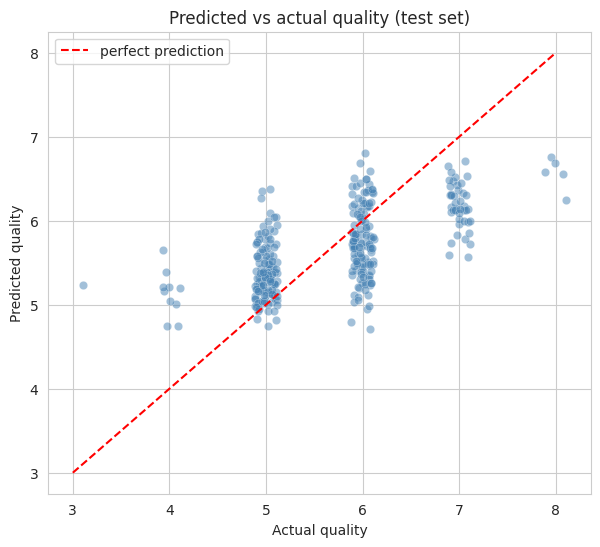

In [21]:
rng = np.random.default_rng(42)
jitter = rng.uniform(-0.12, 0.12, size=len(y_test))   # quality is whole numbers so points would stack, jitter spreads them

plt.figure(figsize=(7, 6))
plt.scatter(y_test + jitter, y_pred, alpha=0.5, color="steelblue", edgecolor="white", linewidth=0.3)
plt.plot([3, 8], [3, 8], "r--", label="perfect prediction")
plt.xlabel("Actual quality")
plt.ylabel("Predicted quality")
plt.title("Predicted vs actual quality (test set)")
plt.legend()
plt.show()

In [22]:
comp = pd.DataFrame({"actual": y_test.values, "predicted": y_pred})
print(comp.groupby("actual")["predicted"].agg(["count", "mean", "min", "max"]).round(2))

err = np.abs(comp["actual"] - comp["predicted"])
print("\nwithin +-0.5 of the true score:", round((err <= 0.5).mean() * 100, 1), "%")
print("within +-1.0 of the true score:", round((err <= 1.0).mean() * 100, 1), "%")
print("range of predictions:", round(y_pred.min(), 2), "to", round(y_pred.max(), 2))

        count  mean   min   max
actual                         
3           1  5.23  5.23  5.23
4          10  5.14  4.74  5.65
5         130  5.38  4.74  6.38
6         132  5.76  4.71  6.80
7          42  6.18  5.57  6.71
8           5  6.56  6.24  6.76

within +-0.5 of the true score: 57.2 %
within +-1.0 of the true score: 88.8 %
range of predictions: 4.71 to 6.8


**What the plot shows and the limitations of the model**

1. **Predictions are squashed toward the middle.** If the model was perfect all points would sit on the red line. Instead the cloud is flatter than the line: the predictions only range from about 4.7 to 6.8, so the model never predicts a 3 or an 8. Low quality wines are over-predicted (the actual 3s and 4s get predicted around 5.1 to 5.2 on average) and the best wines are under-predicted (actual 7s are predicted about 6.2 and actual 8s about 6.6 on average). This is the usual regression-to-the-mean effect and it is made worse by having so few extreme samples.
2. **Wide scatter at every level.** For an actual score of 6 the predictions go from roughly 4.7 to 6.8. Only about 57% of the test wines are predicted within 0.5 of the real score, and about 89% within 1 point.
3. **It is a straight line model.** Linear regression assumes each attribute has a constant effect. Real chemistry can have interactions and thresholds between the measurements, which this cannot capture.
4. **The target is a whole number score** (an ordered category) but we predict a continuous value, so the prediction is not directly a valid score.

# Task 4 - Business decision-making

### 4a. Two measurements to focus on in lab screening

I would recommend:

1. **Alcohol content.** It is the strongest single correlate of quality (r = +0.48), it has the largest standardized coefficient (+0.30) and its VIF is low, so the effect is not an artefact of collinearity. It is also cheap and easy to measure accurately in a lab. In this data about two thirds of the wines below 10% alcohol are rated 5, while among wines at 11.5% or more only about 10% are rated 5 or lower, so a low reading could be a flag for a wine that needs a closer sensory look.
2. **Volatile acidity.** Second strongest (r = -0.39, standardized coefficient -0.18) and low VIF. It has a clear meaning (acetic acid, vinegar taint), so a high reading is a sensible reason to flag or hold a batch.

Sulphates would be the next one to watch (r = +0.25, standardized coefficient +0.15) if the lab can add a third test.

### 4b. Can the model replace sensory evaluation?

In [23]:
print(f"R^2  = {r2:.3f}")
print(f"RMSE = {rmse:.3f}")
print(f"MAE  = {mae:.3f}")
print(f"Share within +-0.5 : {(err <= 0.5).mean():.1%}")
print(f"Share within +-1.0 : {(err <= 1.0).mean():.1%}")

R^2  = 0.403
RMSE = 0.625
MAE  = 0.504
Share within +-0.5 : 57.2%
Share within +-1.0 : 88.8%


**No, the model is not reliable enough to replace sensory evaluation.** My reasons from the test set:

- **R-squared of 0.40** means 60% of the variation in quality is unexplained. A tool replacing human tasters should explain far more than that.
- **RMSE of 0.62 and MAE of 0.50:** the typical error is about half a point and sometimes more than a point. The scores that matter commercially are only a point or two apart (5 vs 6 vs 7), so an error this size can easily move a wine into the wrong grade.
- Only about **57% of predictions are within 0.5** of the real score. Around 1 in 10 are off by more than a full point.
- The model cannot identify the **best and worst wines** at all, because it never predicts below about 4.7 or above about 6.8, and those are exactly the wines a company cares most about.

**What I would suggest instead:** use the model (or simply the alcohol and volatile acidity readings) as a **cheap first screening step** to flag batches that look unusual, and keep the sensory panel for the final decision. That reduces how many wines need tasting without removing the experts.

### 4c. Limitations of the dataset and the approach

1. **The quality scores are subjective and the data is imbalanced.** Each score is the median of at least 3 expert opinions, so it contains human noise and personal taste that no chemical measurement can predict, which puts a ceiling on how good any model can get. Also about 83% of the wines are rated 5 or 6, with very few 3s and 8s, so the model has little to learn from at the extremes. The dataset also has 240 duplicate rows, which may make the test score look a bit more optimistic because the same row can end up in both train and test.
2. **Limited scope and a simple model.** The data only covers red Vinho Verde from one region, and there is no information on grape type, vineyard, vintage, brand or price (the `.names` file says this too), so the results should not be generalized to other wines. On the modelling side, I only used linear regression, which assumes straight line effects, treats the ordered score as a continuous number, and is affected by correlated inputs like fixed acidity and density. The results also come from a single train/test split with `random_state=42`, so the numbers could change a little with a different split.

**Possible next steps:** try non-linear models (random forest, gradient boosting), treat it as a classification problem (for example good vs not good wine), use cross-validation, and compare with the white wine file.

## Conclusion

- Alcohol (positive) and volatile acidity (negative) are the two attributes most associated with red wine quality.
- A linear regression using all 11 lab measurements gives R-squared of about 0.40 and RMSE of about 0.62 on the test set.
- That is useful for screening but not accurate enough to replace the sensory panel.